<a href="https://colab.research.google.com/github/saopa28/INSE-6450/blob/main/Milestone2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Training

## 1. Setup

In [2]:
import os, urllib.request, time, resource, sys, numpy as np, pandas as pd, xgboost as xgb, sklearn, psutil
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, log_loss, brier_score_loss, precision_recall_curve,
                             mean_squared_error, mean_absolute_error, r2_score)
pd.set_option("display.float_format", "{:.6f}".format)

# ---- Versioned configuration ----
DATA_PATH = "https://github.com/saopa28/INSE-6450/releases/download/v1.0-engineered/criteo_uplift_engineered.zip"
ENGINEERED = True
TARGET    = "conversion"
SAMPLE_N  = None
SEED      = 42
CURVE_TRAIN_ROWS = None

RAW = [f"f{i}" for i in range(12)]
FEATS = RAW + ["f4_x_f9", "f4_x_f11", "f9_x_f11", "f4_squared", "f9_squared", "f11_squared"]

# Stage 1 classifiers (mu1, mu0)
CLF = dict(n_estimators=1000, learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8,
           colsample_bytree=0.8, tree_method="hist", eval_metric="logloss", early_stopping_rounds=30,
           n_jobs=-1, random_state=SEED)

# Stage 2 regressors (tau1, tau0)
REG = dict(n_estimators=1000, learning_rate=0.05, max_depth=4, min_child_weight=50, subsample=0.8,
           colsample_bytree=0.8, reg_lambda=5.0, tree_method="hist", early_stopping_rounds=30,
           n_jobs=-1, random_state=SEED)

# Manual tuning
RUNS = [("1. Baseline", {}, {}),
        ("2. Stage 1 max_depth 6 -> 4", {"max_depth": 4}, {}),
        ("3. Stage 1 max_depth 6 -> 8", {"max_depth": 8}, {}),
        ("4. Stage 2 min_child_weight 50 -> 200", {}, {"min_child_weight": 200}),
        ("5. learning_rate 0.05 -> 0.1", {"learning_rate": 0.1}, {"learning_rate": 0.1})]

## 2. Data featuring and stratified split

In [ ]:
cols = (FEATS if ENGINEERED else RAW) + ["treatment", "conversion", "visit"]
df = pd.read_csv(DATA_PATH, compression="zip", usecols=cols, dtype={c: "float32" for c in cols if c in FEATS})
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns")

strata = lambda d: d.treatment.astype(int) * 2 + d[TARGET].astype(int)
tr, rest = train_test_split(df, test_size=0.30, stratify=strata(df), random_state=SEED)
va, te = train_test_split(rest, test_size=0.50, stratify=strata(rest), random_state=SEED)
arr = lambda d: (d[FEATS].to_numpy(np.float32), d.treatment.to_numpy(np.int8), d[TARGET].to_numpy(np.int8))
(Xtr, ttr, ytr), (Xva, tva, yva), (Xte, tte, yte) = arr(tr), arr(va), arr(te)
del df, tr, va, te, rest
print(f"train={len(ytr):,} val={len(yva):,} test={len(yte):,} | {TARGET}={ytr.mean():.4%} | treated={ttr.mean():.2%}")

## 3. Functions

In [ ]:
def gain_curve(y, t, s, auuc=False):
    o = np.argsort(-s, kind="stable"); y, t = y[o], t[o]
    nt, nc, yt, yc = np.cumsum(t), np.cumsum(1 - t), np.cumsum(y * t), np.cumsum(y * (1 - t))
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.nan_to_num(yt / nt - yc / nc) * (nt + nc) if auuc else yt - yc * np.where(nc > 0, nt / nc, 0)

def qini(y, t, s, auuc=False):
    q = gain_curve(y, t, s, auuc); n = len(q)
    return float(np.mean(q - np.linspace(q[-1] / n, q[-1], n)) / n)

def uplift_at(y, t, s, k):
    top = np.argsort(-s, kind="stable")[: int(len(s) * k)]
    return float(y[top][t[top] == 1].mean() - y[top][t[top] == 0].mean())

def boot(y, t, s, s2=None, n=100):
    rng, vals = np.random.default_rng(SEED), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        vals.append(qini(y[i], t[i], s[i]) - (qini(y[i], t[i], s2[i]) if s2 is not None else 0))
    return np.percentile(vals, [2.5, 97.5]), float(np.mean(np.array(vals) > 0))

# ---------- X-learner ----------
def fit_x(Xtr, Xva, clf=CLF, reg=REG, weighted=False, curves=False):
    T, C, Tv, Cv = ttr == 1, ttr == 0, tva == 1, tva == 0
    sub = lambda X, y: (X[:300_000], y[:300_000])
    ev = lambda X, y, Xv, yv: ([sub(X, y)] if curves else []) + [(Xv, yv)]
    w = lambda y: {"scale_pos_weight": (y == 0).sum() / (y == 1).sum()} if weighted else {}

      # Stage 1: outcome model per group
    mu1 = xgb.XGBClassifier(**clf, **w(ytr[T])).fit(Xtr[T], ytr[T], eval_set=ev(Xtr[T], ytr[T], Xva[Tv], yva[Tv]), verbose=False)
    mu0 = xgb.XGBClassifier(**clf, **w(ytr[C])).fit(Xtr[C], ytr[C], eval_set=ev(Xtr[C], ytr[C], Xva[Cv], yva[Cv]), verbose=False)

      # Stage 2: imputed effects, filled in by the OTHER group's model
    D1, D1v = ytr[T] - mu0.predict_proba(Xtr[T])[:, 1], yva[Tv] - mu0.predict_proba(Xva[Tv])[:, 1]
    D0, D0v = mu1.predict_proba(Xtr[C])[:, 1] - ytr[C], mu1.predict_proba(Xva[Cv])[:, 1] - yva[Cv]
    tau1 = xgb.XGBRegressor(**reg).fit(Xtr[T], D1, eval_set=ev(Xtr[T], D1, Xva[Tv], D1v), verbose=False)
    tau0 = xgb.XGBRegressor(**reg).fit(Xtr[C], D0, eval_set=ev(Xtr[C], D0, Xva[Cv], D0v), verbose=False)
    return dict(mu1=mu1, mu0=mu0, tau1=tau1, tau0=tau0, g=float(ttr.mean()))

pred_x = lambda m, X: m["g"] * m["tau0"].predict(X) + (1 - m["g"]) * m["tau1"].predict(X)
trees = lambda m: "/".join(str(m[k].best_iteration + 1) for k in ["mu1", "mu0", "tau1", "tau0"])
size_mb = lambda *ms: sum(len(m.get_booster().save_raw("ubj")) for m in ms) / 1e6

## 4. Manual tuning (validation)

In [ ]:
rows = []
for name, c, r in RUNS:
    t0 = time.perf_counter(); m = fit_x(Xtr, Xva, {**CLF, **c}, {**REG, **r}); secs = time.perf_counter() - t0
    s = pred_x(m, Xva)
    rows.append(dict(run=name, val_qini=qini(yva, tva, s), val_uplift_10=uplift_at(yva, tva, s, 0.1),
                     trees=trees(m), train_s=round(secs, 1), clf={**CLF, **c}, reg={**REG, **r}))
tuning = pd.DataFrame(rows)
best = tuning.loc[tuning.val_qini.idxmax()]
chosen, clf_best, reg_best = best.run, best.clf, best.reg
display(tuning.drop(columns=["clf", "reg"]))
print("Selected:", chosen)

,run,val_qini,val_uplift_10,trees,train_s
0,1. Baseline,0.000390,0.008259,279/103/130/46,580.600000
1,2. Stage 1 max_depth 6 -> 4,0.000388,0.008127,468/197/123/49,686.000000
2,3. Stage 1 max_depth 6 -> 8,0.000378,0.008021,136/85/137/31,450.900000
3,4. Stage 2 min_child_weight 50 -> 200,0.000388,0.008195,279/103/125/31,557.700000
4,5. learning_rate 0.05 -> 0.1,0.000405,0.008427,244/55/84/19,460.800000


Selected: 5. learning_rate 0.05 -> 0.1


## 5. Model training, Qini curve (test)

model,X-learner,Response model
val_qini,0.000405,0.000391
test_qini,0.000376,0.000390
test_qini_95CI,"[0.000319, 0.000442]","[0.000329, 0.000457]"
test_uplift@10%,0.007954,0.007976
train_s,478.000000,377.700000
infer_us_per_user,1.878000,5.093000
model_MB,0.242000,1.017000


Qini(X-learner) - Qini(Response): 95% CI [-3.8e-05  8.0e-06], X-learner better in 12%
Trees: 244/55/84/19 | all 4 models: 1.460 MB | peak RAM: 8.73 GB


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


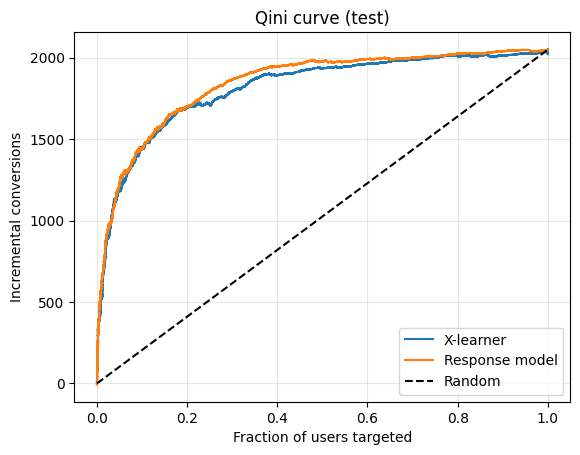

In [ ]:
t0 = time.perf_counter(); xl = fit_x(Xtr, Xva, clf_best, reg_best, curves=True); xl_train = time.perf_counter() - t0
t0 = time.perf_counter(); s_te = pred_x(xl, Xte); xl_inf = time.perf_counter() - t0
s_va = pred_x(xl, Xva)

t0 = time.perf_counter(); resp = xgb.XGBClassifier(**clf_best).fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
r_train = time.perf_counter() - t0
t0 = time.perf_counter(); r_te = resp.predict_proba(Xte)[:, 1]; r_inf = time.perf_counter() - t0
r_va = resp.predict_proba(Xva)[:, 1]

def row(name, sv, st, tr_s, inf_s, mb):
    return {"model": name, "val_qini": qini(yva, tva, sv), "test_qini": qini(yte, tte, st),
            "test_qini_95CI": boot(yte, tte, st)[0].round(6), "test_uplift@10%": uplift_at(yte, tte, st, 0.1),
            "train_s": round(tr_s, 1), "infer_us_per_user": round(1e6 * inf_s / len(yte), 3), "model_MB": round(mb, 3)}
display(pd.DataFrame([row("X-learner", s_va, s_te, xl_train, xl_inf, size_mb(xl["tau0"], xl["tau1"])),
                      row("Response model", r_va, r_te, r_train, r_inf, size_mb(resp))]).set_index("model").T)
ci, p = boot(yte, tte, s_te, r_te)
print(f"Qini(X-learner) - Qini(Response): 95% CI {ci.round(6)}, X-learner better in {p:.0%}")
print(f"Trees: {trees(xl)} | all 4 models: {size_mb(xl['mu1'], xl['mu0'], xl['tau1'], xl['tau0']):.3f} MB | "
      f"peak RAM: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.2f} GB")

# Qini curves on the test set
x = np.linspace(0, 1, len(yte)); q = gain_curve(yte, tte, s_te)
plt.plot(x, q, label="X-learner"); plt.plot(x, gain_curve(yte, tte, r_te), label="Response model")
plt.plot([0, 1], [0, q[-1]], "k--", label="Random")
plt.xlabel("Fraction of users targeted"); plt.ylabel("Incremental conversions"); plt.title("Qini curve (test)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 6. Learning curves

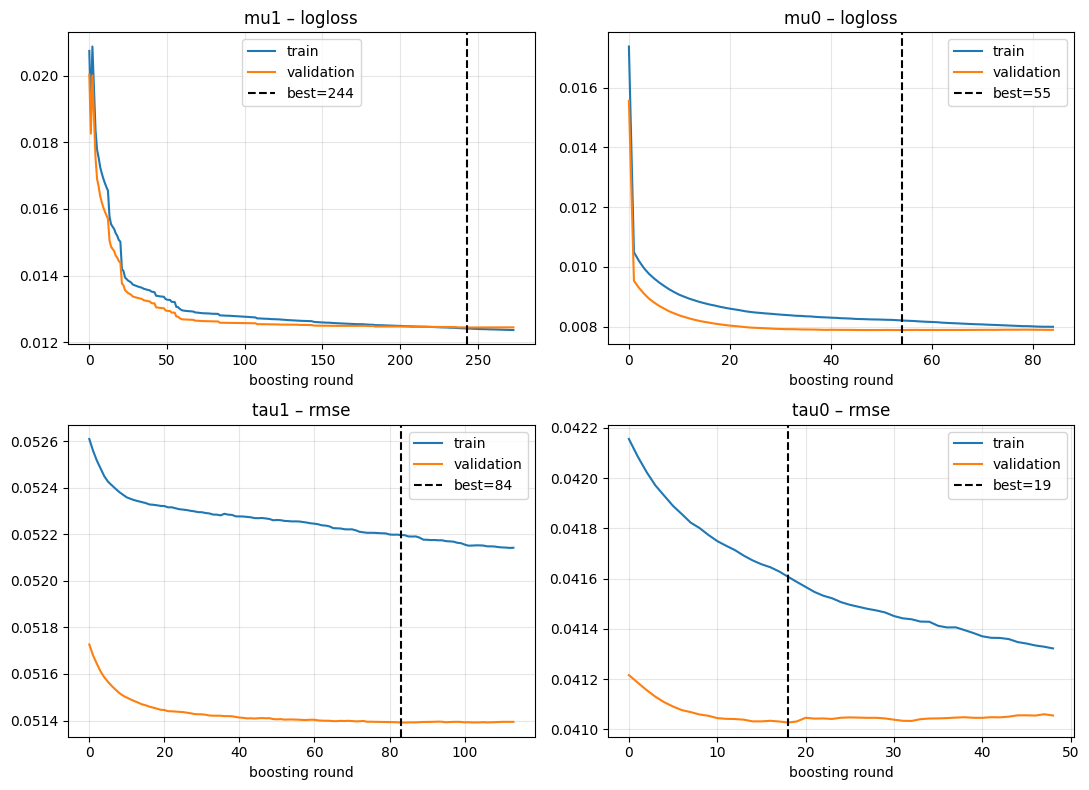

,model,metric,rounds_run,best_round,train_at_best,val_at_best
0,mu1,logloss,274,244,0.012412,0.012442
1,mu0,logloss,85,55,0.008205,0.007882
2,tau1,rmse,114,84,0.052197,0.051391
3,tau0,rmse,49,19,0.041608,0.041027


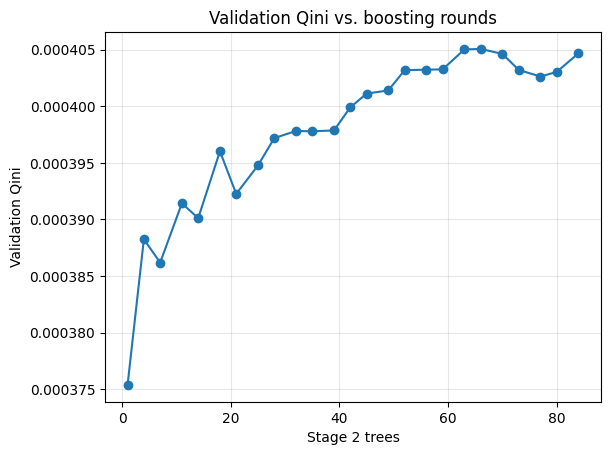

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8)); rows = []
for ax, k in zip(axes.ravel(), ["mu1", "mu0", "tau1", "tau0"]):
    ev = xl[k].evals_result(); met = list(ev["validation_0"])[0]
    a, b, best_i = ev["validation_0"][met], ev["validation_1"][met], xl[k].best_iteration
    ax.plot(a, label="train"); ax.plot(b, label="validation"); ax.axvline(best_i, c="k", ls="--", label=f"best={best_i + 1}")
    ax.set(title=f"{k} – {met}", xlabel="boosting round"); ax.legend(); ax.grid(alpha=0.3)
    rows.append(dict(model=k, metric=met, rounds_run=len(b), best_round=best_i + 1, train_at_best=a[best_i], val_at_best=b[best_i]))
plt.tight_layout(); plt.show(); display(pd.DataFrame(rows))

b0, b1 = xl["tau0"].best_iteration + 1, xl["tau1"].best_iteration + 1
steps = np.unique(np.linspace(1, max(b0, b1), 25).astype(int))
qs = [qini(yva, tva, xl["g"] * xl["tau0"].predict(Xva, iteration_range=(0, min(k, b0)))
           + (1 - xl["g"]) * xl["tau1"].predict(Xva, iteration_range=(0, min(k, b1)))) for k in steps]
plt.plot(steps, qs, marker="o"); plt.xlabel("Stage 2 trees"); plt.ylabel("Validation Qini")
plt.title("Validation Qini vs. boosting rounds"); plt.grid(alpha=0.3); plt.show()

## 7. Ablation

In [ ]:
base = fit_x(Xtr, Xva)
raw = fit_x(Xtr[:, :12], Xva[:, :12], clf_best, reg_best)
rnd = np.random.default_rng(SEED).random(len(yte))
variants = {"Final X-learner": (s_va, s_te),
            "Baseline config": (pred_x(base, Xva), pred_x(base, Xte)),
            "Without engineered features": (pred_x(raw, Xva[:, :12]), pred_x(raw, Xte[:, :12])),
            "Response model": (r_va, r_te),
            "Random targeting": (None, rnd)}
display(pd.DataFrame([{"variant": n, "val_qini": qini(yva, tva, sv) if sv is not None else np.nan,
                       "test_qini": qini(yte, tte, st), "test_qini_95CI": boot(yte, tte, st)[0].round(6),
                       "test_uplift@10%": uplift_at(yte, tte, st, 0.1)} for n, (sv, st) in variants.items()]))
for n in ["Baseline config", "Without engineered features", "Response model"]:
    ci, p = boot(yte, tte, s_te, variants[n][1])
    print(f"Final - {n}: 95% CI {ci.round(6)}, final better in {p:.0%}")

,variant,val_qini,test_qini,test_qini_95CI,test_uplift@10%
0,Final X-learner,0.000405,0.000376,"[0.000319, 0.000442]",0.007954
1,Baseline config,0.000390,0.000382,"[0.000332, 0.000449]",0.008118
2,Without engineered features,0.000386,0.000381,"[0.000323, 0.000455]",0.008006
3,Response model,0.000391,0.000390,"[0.000329, 0.000457]",0.007976
4,Random targeting,NaN,0.000011,"[-3.6e-05, 5.5e-05]",0.001236


Final - Baseline config: 95% CI [-2.8e-05  1.3e-05], final better in 23%
Final - Without engineered features: 95% CI [-2.7e-05  1.3e-05], final better in 32%
Final - Response model: 95% CI [-3.8e-05  8.0e-06], final better in 12%


## 8. Class imbalance

In [ ]:
wx = fit_x(Xtr, Xva, clf_best, reg_best, weighted=True)
Tv, Cv = tva == 1, tva == 0
display(pd.DataFrame({n: {"mu1_mean_pred_val": m["mu1"].predict_proba(Xva[Tv])[:, 1].mean(), "treated_actual_val": yva[Tv].mean(),
                          "mu0_mean_pred_val": m["mu0"].predict_proba(Xva[Cv])[:, 1].mean(), "control_actual_val": yva[Cv].mean(),
                          "mean_pred_uplift_test": pred_x(m, Xte).mean(), "actual_uplift_test": yte[tte == 1].mean() - yte[tte == 0].mean(),
                          "val_qini": qini(yva, tva, pred_x(m, Xva)), "test_qini": qini(yte, tte, pred_x(m, Xte))}
                      for n, m in [("No re-weighting (chosen)", xl), ("Re-weighting", wx)]}))

,No re-weighting (chosen),Re-weighting
mu1_mean_pred_val,0.003087,0.120721
treated_actual_val,0.003090,0.003090
mu0_mean_pred_val,0.001990,0.047800
control_actual_val,0.001936,0.001936
mean_pred_uplift_test,0.000942,0.093264
actual_uplift_test,0.001150,0.001150
val_qini,0.000405,0.000395
test_qini,0.000376,0.000372


## 9. Task metrics (validation and test)

In [ ]:
splits = {"val": (Xva, tva, yva), "test": (Xte, tte, yte)}
display(pd.DataFrame({sp: {"Qini": qini(y, t, s := pred_x(xl, X)), "AUUC": qini(y, t, s, auuc=True),
                           "uplift@10%": uplift_at(y, t, s, 0.1), "uplift@20%": uplift_at(y, t, s, 0.2),
                           "uplift@30%": uplift_at(y, t, s, 0.3), "avg_uplift": y[t == 1].mean() - y[t == 0].mean()}
                      for sp, (X, t, y) in splits.items()}).T)

def clf_metrics(y, p, thr):
    yh = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y, yh), "precision": precision_score(y, yh, zero_division=0),
            "recall": recall_score(y, yh), "F1": f1_score(y, yh), "F1_macro": f1_score(y, yh, average="macro"),
            "F1_micro": f1_score(y, yh, average="micro"), "AUROC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p), "log_loss": log_loss(y, p), "Brier": brier_score_loss(y, p),
            "positive_rate": y.mean(), "threshold": thr}

out = {}
for name, m, grp in [("mu1", xl["mu1"], 1), ("mu0", xl["mu0"], 0), ("response", resp, None)]:
    pick = lambda t: (t == grp) if grp is not None else np.ones_like(t, bool)
    pv = m.predict_proba(Xva[pick(tva)])[:, 1]
    pr, rc, th = precision_recall_curve(yva[pick(tva)], pv)
    thr = th[np.argmax(2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-12))]
    for sp, (X, t, y) in splits.items():
        out[(name, sp)] = clf_metrics(y[pick(t)], m.predict_proba(X[pick(t)])[:, 1], thr)
display(pd.DataFrame(out))

out = {}
for name, grp in [("tau1", 1), ("tau0", 0)]:
    for sp, (X, t, y) in splits.items():
        Xg, yg = X[t == grp], y[t == grp]
        D = yg - xl["mu0"].predict_proba(Xg)[:, 1] if grp else xl["mu1"].predict_proba(Xg)[:, 1] - yg
        p = xl[name].predict(Xg)
        out[(name, sp)] = {"RMSE": np.sqrt(mean_squared_error(D, p)), "MAE": mean_absolute_error(D, p),
                           "R2": r2_score(D, p), "RMSE_mean_baseline": D.std()}
display(pd.DataFrame(out))

,Qini,AUUC,uplift@10%,uplift@20%,uplift@30%,avg_uplift
val,0.000405,0.000472,0.008427,0.004792,0.003518,0.001153
test,0.000376,0.000438,0.007954,0.004702,0.003335,0.001150


mu1               mu0          response         
                   val     test      val     test      val     test
accuracy      0.995393 0.995402 0.997228 0.997120 0.995654 0.995637
precision     0.285873 0.287632 0.316597 0.284257 0.282691 0.278815
recall        0.327765 0.330730 0.372742 0.319672 0.318836 0.312459
F1            0.305389 0.307679 0.342383 0.300926 0.299677 0.294680
F1_macro      0.651539 0.652686 0.670497 0.649741 0.648749 0.646246
F1_micro      0.995393 0.995402 0.997228 0.997120 0.995654 0.995637
AUROC         0.959298 0.957441 0.965001 0.962190 0.958064 0.955528
PR-AUC        0.221208 0.219771 0.243063 0.210531 0.214657 0.206155
log_loss      0.012442 0.012509 0.007882 0.008188 0.011910 0.012096
Brier         0.002671 0.002669 0.001638 0.001689 0.002533 0.002551
positive_rate 0.003090 0.003089 0.001936 0.001939 0.002917 0.002917
threshold     0.164568 0.164568 0.151249 0.151249 0.160041 0.160041

tau1              tau0         
                        val     test      val     test
RMSE               0.051391 0.051461 0.041027 0.041200
MAE                0.005268 0.005274 0.003495 0.003482
R2                 0.015087 0.015805 0.011277 0.009904
RMSE_mean_baseline 0.051783 0.051873 0.041261 0.041406